# 06_degradation_sensitivity.ipynb

Task 4.2. Đo độ nhạy của reference model ConvNeXt-Tiny với 42 điều kiện suy giảm của benchmark 4.1: macro F1 kèm khoảng tin cậy bootstrap, kiểm định McNemar ghép cặp, recall và confusion theo lớp, các mẫu đổi từ đúng sang sai, thống kê chất lượng ảnh của các mức.

Model đóng băng, không train lại. Notebook chạy validation trước để kiểm tra đường chạy khớp bảng hiệu chỉnh 4.1, rồi mở tập test một lần với `FINAL_EVAL=1`. Đây là lần đầu tập test được mở. Mức suy giảm đã khóa, không chỉnh theo kết quả.

Đầu ra chính: bảng ưu tiên cho task 4.5 (`priority_for_4_5.json`) xếp hạng các họ suy giảm theo mức giảm điểm, đánh dấu họ đã giảm đáng kể ngay ở mức nhẹ, và ghi task xử lý từng họ.

## 1. Môi trường

Internet để On. Accelerator chọn GPU (T4). Dataset input cần hai cái: `cthng123/durian-leaf-disease-dataset` và dataset chứa checkpoint `convnext_tiny_seed42.pt` (cùng hai dataset đã dùng cho notebook 05). Muốn đối chiếu chất lượng ảnh với bộ Vietnamese durian leaf thì add thêm dataset đó và đặt đường dẫn ở mục 9.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "degradation-sensitivity-analysis"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")

Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: degradation-sensitivity-analysis
Commit: e5c7a29
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Model và cấu hình

Nạp reference model và danh sách 42 điều kiện từ `configs/corruption.yaml`.

In [2]:
import json
import os
import time

import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image, display

from src.corruption import load_conditions, load_seed
from src.evaluation.processing_benchmark import ImageCache
from src.evaluation.reference import collect_checkpoint, load_trained_model
from src.evaluation.sensitivity import (
    collect_predictions, compare_splits, condition_table, confusion_matrices, external_quality, family_summary, flip_destinations,
    sample_flips, image_quality, load_config, priority_for_next_task, quality_summary, recorded_calibration,
)
from src.evaluation.sensitivity_plots import (
    plot_class_recall_change, plot_confusion_grid, plot_degradation_heatmap, plot_flip_counts, plot_flip_destinations,
    plot_sample_flips, plot_priority, plot_quality_curves, plot_severity_curves, plot_val_vs_test,
)
from src.training.loop import resolve_device

FIG = REPO_DIR / "outputs/figures/sensitivity"
RES = REPO_DIR / "outputs/results/sensitivity"
REP = REPO_DIR / "reports/sensitivity"
for folder in (FIG, RES, REP):
    folder.mkdir(parents=True, exist_ok=True)


def show(path):
    display(Image(filename=str(path)))


LIMIT = None
cfg = load_config()
pipeline_cfg = yaml.safe_load((REPO_DIR / "configs/pipeline.yaml").read_text(encoding="utf-8"))
classes = list(pipeline_cfg["classes"])
reference = json.loads((REPO_DIR / "reports/baselines/reference_selection.json").read_text(encoding="utf-8"))["selection"]["reference"]
assert reference == "convnext_tiny", f"Reference model là {reference}, notebook này viết cho convnext_tiny."
train_cfg = yaml.safe_load((REPO_DIR / "configs/train_convnext_tiny.yaml").read_text(encoding="utf-8"))

checkpoint = collect_checkpoint("/kaggle/input", cfg["checkpoint_name"], "/kaggle/working/checkpoints")
device = resolve_device()
model = load_trained_model(train_cfg, checkpoint, len(classes), device)
conditions = load_conditions(cfg["corruption_config"], "val")
seed = load_seed(cfg["corruption_config"])
families = list(dict.fromkeys(spec["family"] for spec in conditions.values()))
print(f"Reference model: {reference}, thiết bị: {device}")
print(f"{len(conditions)} điều kiện thuộc {len(families)} họ, seed {seed}")

Reference model: convnext_tiny, thiết bị: cuda
42 điều kiện thuộc 14 họ, seed 42


## 3. Tái lập trên validation

Chạy ảnh sạch và 42 điều kiện trên validation. Mỗi bộ ảnh được tạo rồi dùng ngay và giải phóng, nên RAM không tăng theo số điều kiện. Cùng lúc đo thống kê chất lượng từng ảnh. Bước này mất khoảng 5 đến 10 phút.

In [3]:
def run_split(split):
    cache = ImageCache(pipeline_cfg, conditions, seed, limit=LIMIT, split=split)
    parts = []

    def measure(name, images):
        frame = image_quality(images)
        frame["condition"] = name
        parts.append(frame)

    start = time.time()
    probs = collect_predictions(model, cache, pipeline_cfg, device, progress=lambda message: print(message, flush=True), quality=measure)
    print(f"{split}: {len(cache)} ảnh, {len(conditions) + 1} bộ ảnh, mất {(time.time() - start) / 60:.1f} phút")
    return cache, probs, pd.concat(parts, ignore_index=True)


cache_val, probs_val, quality_val = run_split("val")

 1/43 clean
 2/43 brightness_dark_s1
 3/43 brightness_dark_s2
 4/43 brightness_dark_s3
 5/43 brightness_bright_s1
 6/43 brightness_bright_s2
 7/43 brightness_bright_s3
 8/43 contrast_low_s1
 9/43 contrast_low_s2
10/43 contrast_low_s3
11/43 blur_s1
12/43 blur_s2
13/43 blur_s3
14/43 noise_s1
15/43 noise_s2
16/43 noise_s3
17/43 contrast_high_s1
18/43 contrast_high_s2
19/43 contrast_high_s3
20/43 glare_s1
21/43 glare_s2
22/43 glare_s3
23/43 shadow_s1
24/43 shadow_s2
25/43 shadow_s3
26/43 lowlight_s1
27/43 lowlight_s2
28/43 lowlight_s3
29/43 motion_blur_s1
30/43 motion_blur_s2
31/43 motion_blur_s3
32/43 sensor_noise_s1
33/43 sensor_noise_s2
34/43 sensor_noise_s3
35/43 jpeg_s1
36/43 jpeg_s2
37/43 jpeg_s3
38/43 lowres_s1
39/43 lowres_s2
40/43 lowres_s3
41/43 color_cast_s1
42/43 color_cast_s2
43/43 color_cast_s3
val: 444 ảnh, 43 bộ ảnh, mất 4.8 phút


### Đối chiếu với bảng hiệu chỉnh 4.1

Macro F1 validation của 42 điều kiện so với bảng trong `reports/corruptions/README.md` (làm tròn 3 chữ số). Lệch dưới 0,002 là khớp. Nếu lệch lớn hơn, dừng.

In [4]:
table_val = condition_table(cache_val.labels, probs_val, classes, conditions, cfg)
recorded = recorded_calibration()
gap = pd.Series({name: float(table_val.set_index("condition").loc[name, "macro_f1"]) - recorded[name] for name in conditions}).abs()
print(f"Macro F1 ảnh sạch validation: {table_val.attrs['clean']['clean_macro_f1']:.4f}")
print(f"Lệch lớn nhất so với bảng 4.1: {gap.max():.4f} ({gap.idxmax()})")
if LIMIT is None:
    assert gap.max() < 0.002, "Đường chạy không khớp bảng hiệu chỉnh 4.1"
    print("Khớp.")

Macro F1 ảnh sạch validation: 0.9775
Lệch lớn nhất so với bảng 4.1: 0.0005 (shadow_s1)
Khớp.


## 4. Đánh giá trên tập test

Bật `FINAL_EVAL=1`, chạy cùng quy trình trên 888 ảnh test. Từ đây trở đi không chỉnh mức, ngưỡng hay cách phân loại theo kết quả. Mất khoảng 10 đến 20 phút.

In [5]:
os.environ["FINAL_EVAL"] = "1"
cache_test, probs_test, quality_test = run_split("test")
names = ["clean", *conditions]
np.savez_compressed(
    RES / "sensitivity_predictions.npz",
    conditions=np.array(names),
    classes=np.array(classes),
    labels_val=cache_val.labels, labels_test=cache_test.labels,
    paths_val=np.array(cache_val.paths), paths_test=np.array(cache_test.paths),
    probs_val=np.stack([probs_val[n] for n in names]).astype(np.float16),
    probs_test=np.stack([probs_test[n] for n in names]).astype(np.float16),
)
print("Đã lưu dự đoán từng ảnh", RES / "sensitivity_predictions.npz")

 1/43 clean
 2/43 brightness_dark_s1
 3/43 brightness_dark_s2
 4/43 brightness_dark_s3
 5/43 brightness_bright_s1
 6/43 brightness_bright_s2
 7/43 brightness_bright_s3
 8/43 contrast_low_s1
 9/43 contrast_low_s2
10/43 contrast_low_s3
11/43 blur_s1
12/43 blur_s2
13/43 blur_s3
14/43 noise_s1
15/43 noise_s2
16/43 noise_s3
17/43 contrast_high_s1
18/43 contrast_high_s2
19/43 contrast_high_s3
20/43 glare_s1
21/43 glare_s2
22/43 glare_s3
23/43 shadow_s1
24/43 shadow_s2
25/43 shadow_s3
26/43 lowlight_s1
27/43 lowlight_s2
28/43 lowlight_s3
29/43 motion_blur_s1
30/43 motion_blur_s2
31/43 motion_blur_s3
32/43 sensor_noise_s1
33/43 sensor_noise_s2
34/43 sensor_noise_s3
35/43 jpeg_s1
36/43 jpeg_s2
37/43 jpeg_s3
38/43 lowres_s1
39/43 lowres_s2
40/43 lowres_s3
41/43 color_cast_s1
42/43 color_cast_s2
43/43 color_cast_s3
test: 888 ảnh, 43 bộ ảnh, mất 9.7 phút
Đã lưu dự đoán từng ảnh /kaggle/working/durian-leaf-disease-robustness/outputs/results/sensitivity/sensitivity_predictions.npz


## 5. Degradation theo họ và mức suy giảm

Macro F1 ảnh sạch kèm khoảng tin cậy 95%, rồi degradation (F1 sạch trừ F1 suy giảm) của từng họ qua ba mức. Dấu sao là khác biệt ghép cặp có ý nghĩa sau hiệu chỉnh Holm trên 42 phép thử.

Macro F1 ảnh sạch test: 0.9645  (95%: 0.9519 đến 0.9762), sai 32/888 ảnh


,family,mean_degradation,max_degradation,degradation_s1,significant_levels,category,early_drop,handlers,rank
0,lowres,0.256,0.314,0.199,3,severe,True,[4.4],1
1,contrast_high,0.250,0.454,0.064,3,severe,True,[4.3],2
2,blur,0.218,0.384,0.012,2,severe,False,[4.4],3
3,contrast_low,0.211,0.525,0.013,2,severe,False,[4.3],4
4,brightness_bright,0.202,0.401,0.031,3,severe,False,[4.3],5
5,lowlight,0.193,0.341,0.078,3,severe,True,"[4.3, 4.4]",6
6,motion_blur,0.190,0.313,0.066,3,severe,True,[4.4],7
7,noise,0.171,0.334,0.014,2,severe,False,[4.4],8
8,brightness_dark,0.150,0.347,0.013,2,moderate,False,[4.3],9
9,sensor_noise,0.146,0.231,0.055,3,moderate,True,[4.4],10


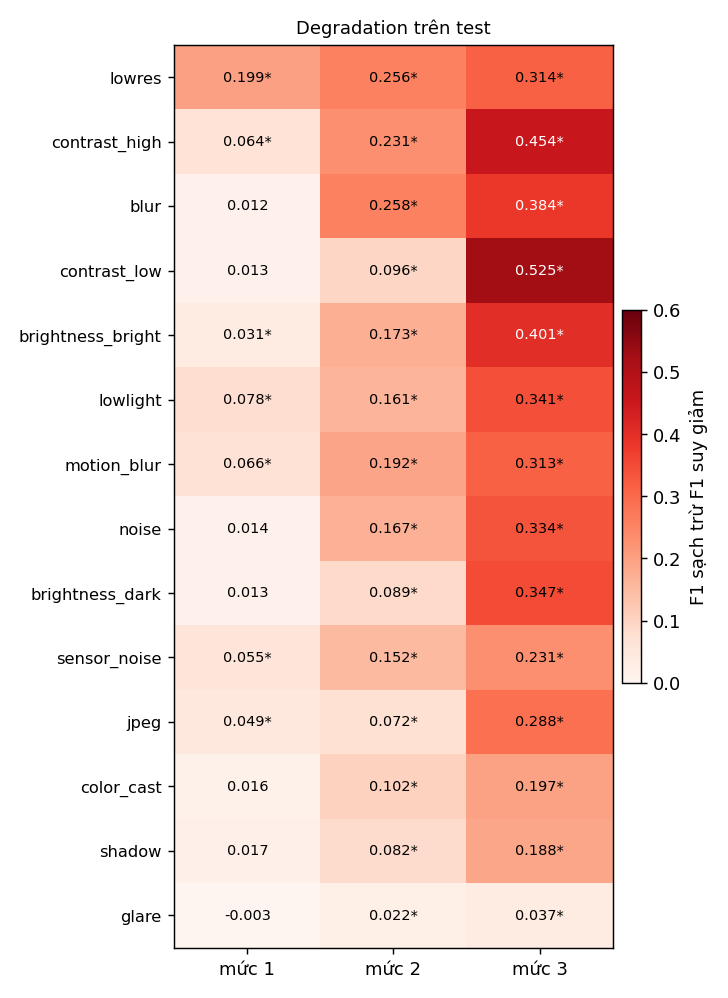

In [6]:
table_test = condition_table(cache_test.labels, probs_test, classes, conditions, cfg)
clean = table_test.attrs["clean"]
print(f"Macro F1 ảnh sạch test: {clean['clean_macro_f1']:.4f}  (95%: {clean['clean_f1_low']:.4f} đến {clean['clean_f1_high']:.4f}), sai {clean['clean_errors']}/{len(cache_test)} ảnh")
summary_test = family_summary(table_test, cfg)
summary_val = family_summary(table_val, cfg)
display(summary_test.drop(columns=["group"]).round(3))
plot_degradation_heatmap(table_test, FIG / "test_degradation_heatmap.png", "Degradation trên test")
show(FIG / "test_degradation_heatmap.png")

### Macro F1 theo mức và khoảng tin cậy

Macro F1 theo mức của từng họ. Vùng xanh là khoảng tin cậy của ảnh sạch. Khi thanh sai số của một mức nằm ngoài vùng xanh thì mức đó thấp hơn ảnh sạch một cách đáng kể.

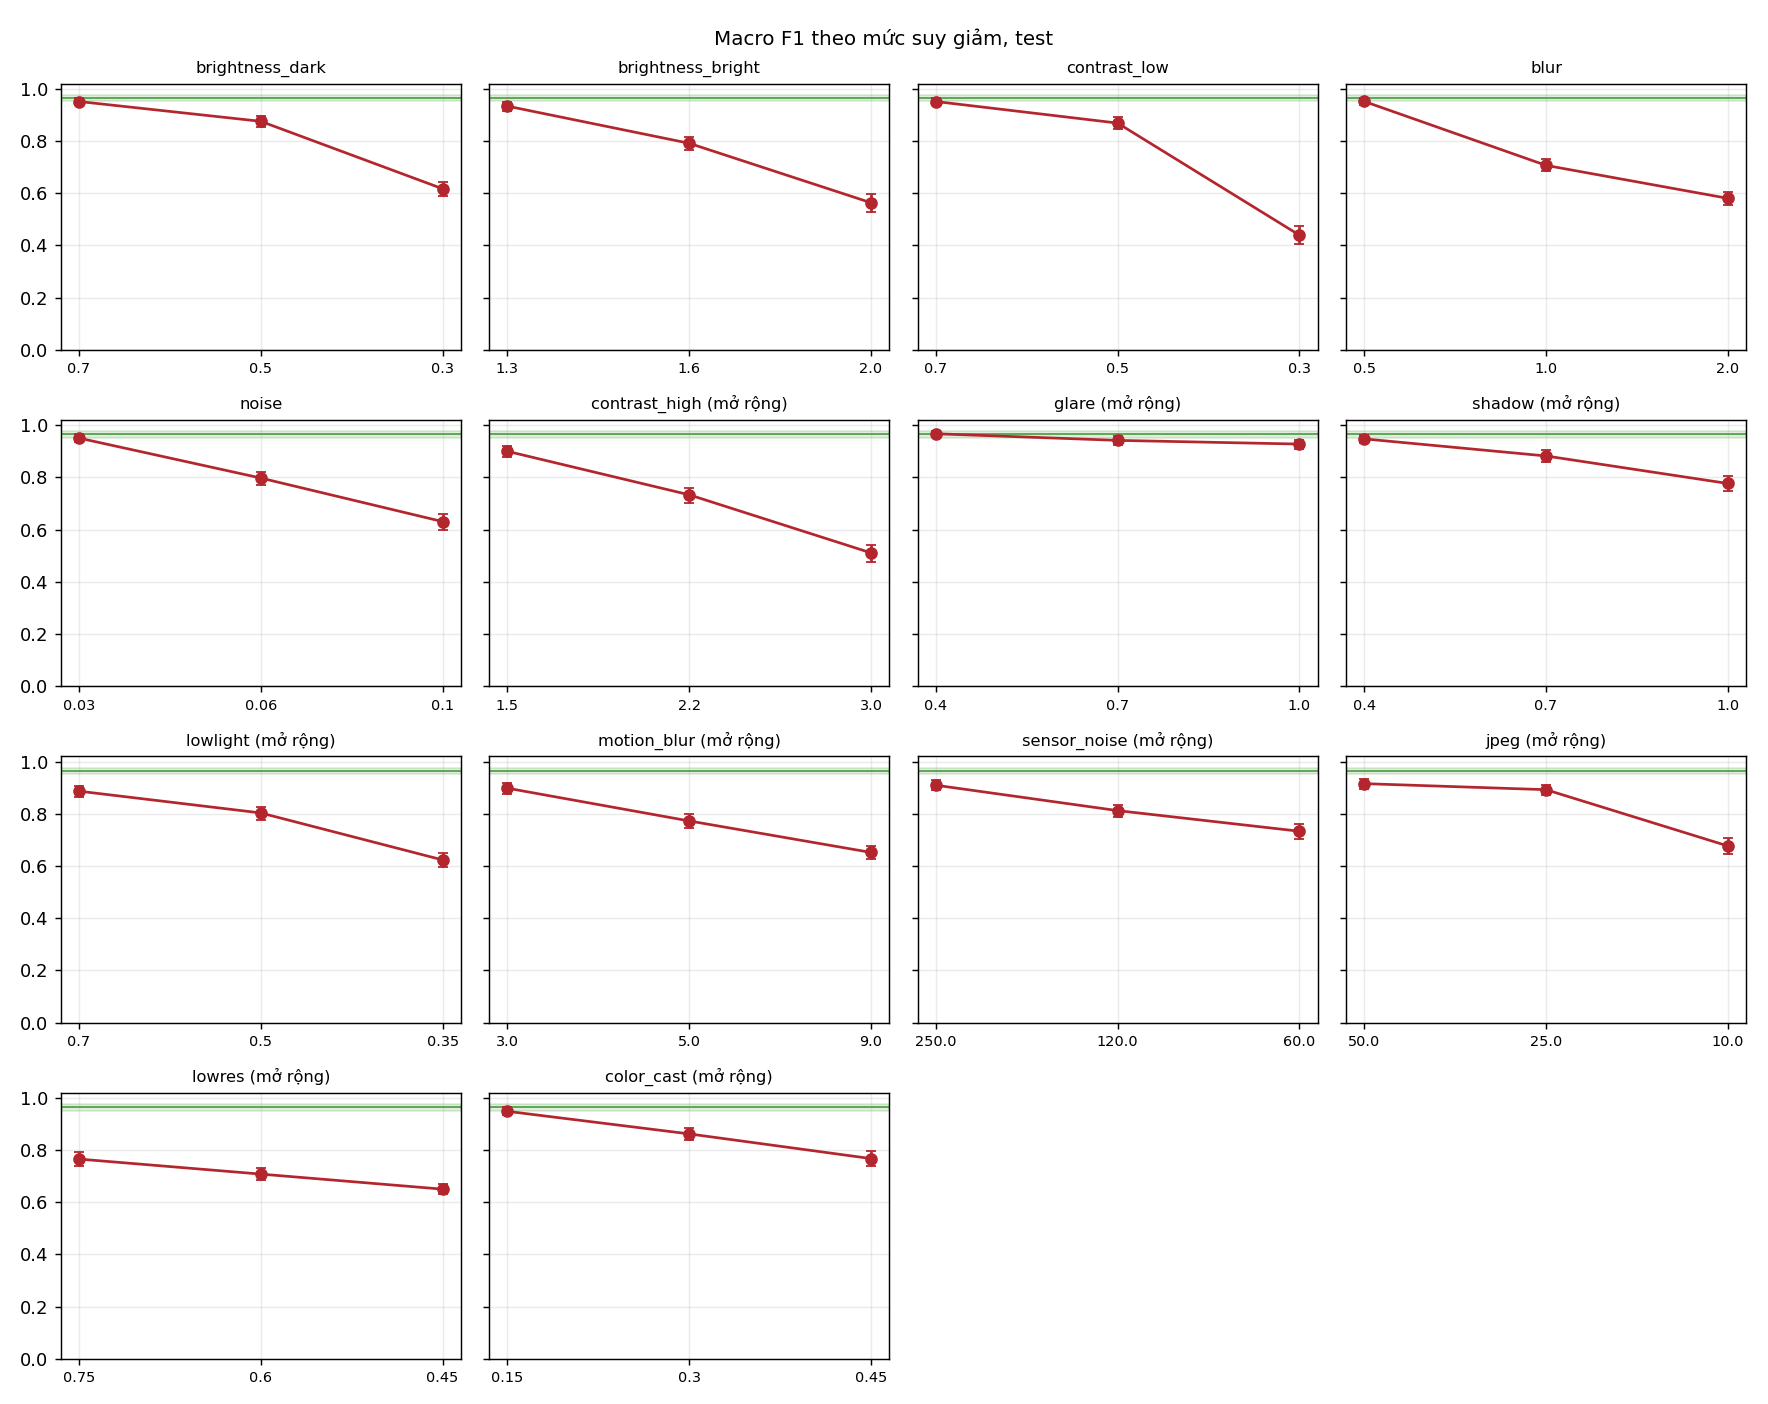

,condition,macro_f1,f1_low,f1_high,degradation,degradation_low,degradation_high,right_to_wrong,wrong_to_right,p_holm
8,contrast_low_s3,0.4393,0.4039,0.4727,0.5252,0.4901,0.5617,437,7,0.0
17,contrast_high_s3,0.5108,0.4775,0.5417,0.4537,0.4225,0.4859,368,9,0.0
5,brightness_bright_s3,0.5636,0.5284,0.5960,0.4009,0.3690,0.4360,358,7,0.0
11,blur_s3,0.5804,0.5566,0.6029,0.3840,0.3608,0.4080,292,6,0.0
2,brightness_dark_s3,0.6172,0.5886,0.6448,0.3473,0.3188,0.3762,277,9,0.0
26,lowlight_s3,0.6231,0.5942,0.6503,0.3414,0.3125,0.3706,285,7,0.0
14,noise_s3,0.6307,0.5971,0.6603,0.3338,0.3036,0.3676,309,7,0.0
38,lowres_s3,0.6505,0.6310,0.6687,0.3140,0.2960,0.3327,218,5,0.0
29,motion_blur_s3,0.6519,0.6258,0.6775,0.3126,0.2856,0.3385,231,7,0.0
35,jpeg_s3,0.6767,0.6447,0.7083,0.2878,0.2556,0.3186,244,8,0.0


In [7]:
plot_severity_curves(table_test, FIG / "test_severity_curves.png", "Macro F1 theo mức suy giảm, test")
show(FIG / "test_severity_curves.png")
columns = ["condition", "macro_f1", "f1_low", "f1_high", "degradation", "degradation_low", "degradation_high", "right_to_wrong", "wrong_to_right", "p_holm"]
display(table_test.sort_values("degradation", ascending=False)[columns].head(15).round(4))

## 6. Kiểm định McNemar ghép cặp

Mỗi điều kiện đếm các ảnh đổi từ đúng sang sai (đỏ) và từ sai sang đúng (xanh) so với ảnh sạch. McNemar chính xác hai phía trên hai số đó, hiệu chỉnh Holm. Điều kiện nhiều ảnh đổi sang sai mà gần như không có ảnh nào đổi ngược là suy giảm thật.

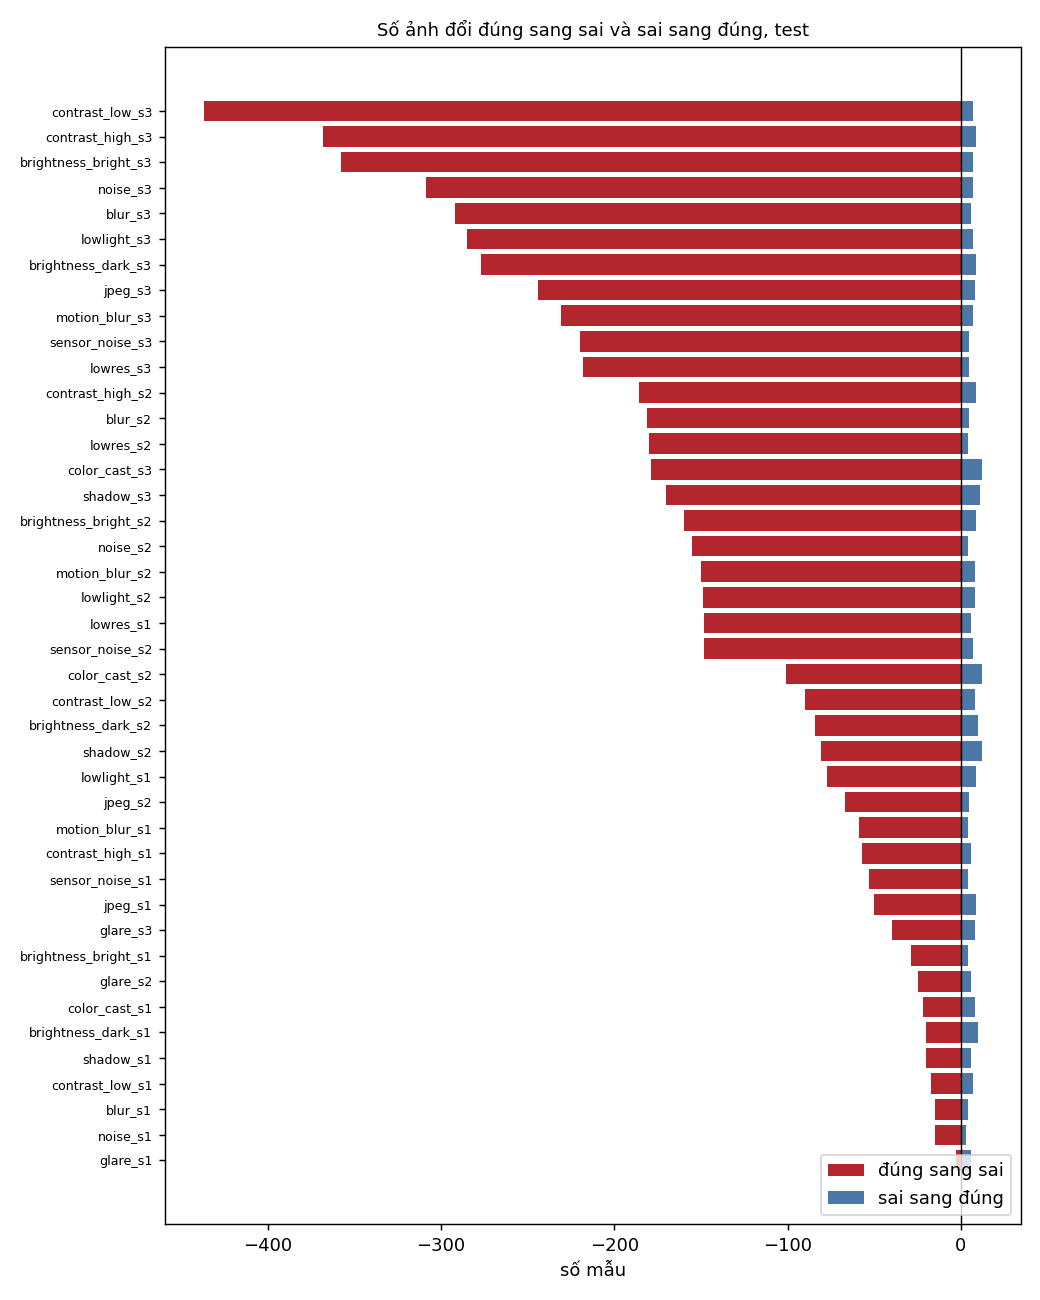

35/42 điều kiện khác ảnh sạch có ý nghĩa (Holm, alpha 0.05)


,condition,degradation,right_to_wrong,wrong_to_right,p_holm
0,brightness_dark_s1,0.0129,20,10,0.1975
6,contrast_low_s1,0.0129,17,7,0.1917
9,blur_s1,0.0125,15,4,0.0806
12,noise_s1,0.0136,15,3,0.0528
18,glare_s1,-0.0029,3,6,0.5078
21,shadow_s1,0.0168,20,6,0.0561
39,color_cast_s1,0.0157,22,8,0.0806


In [8]:
plot_flip_counts(table_test, FIG / "test_flip_counts.png", "Số ảnh đổi đúng sang sai và sai sang đúng, test")
show(FIG / "test_flip_counts.png")
print(f"{int(table_test['significant'].sum())}/{len(table_test)} điều kiện khác ảnh sạch có ý nghĩa (Holm, alpha {cfg['alpha']})")
display(table_test[~table_test["significant"]][["condition", "degradation", "right_to_wrong", "wrong_to_right", "p_holm"]].round(4))

## 7. Phân tích theo lớp

Recall từng lớp của mỗi điều kiện trừ recall ảnh sạch. Hàng sắp theo degradation. Lớp nào đỏ đậm là lớp dễ mất nhất khi chất lượng ảnh xấu đi.

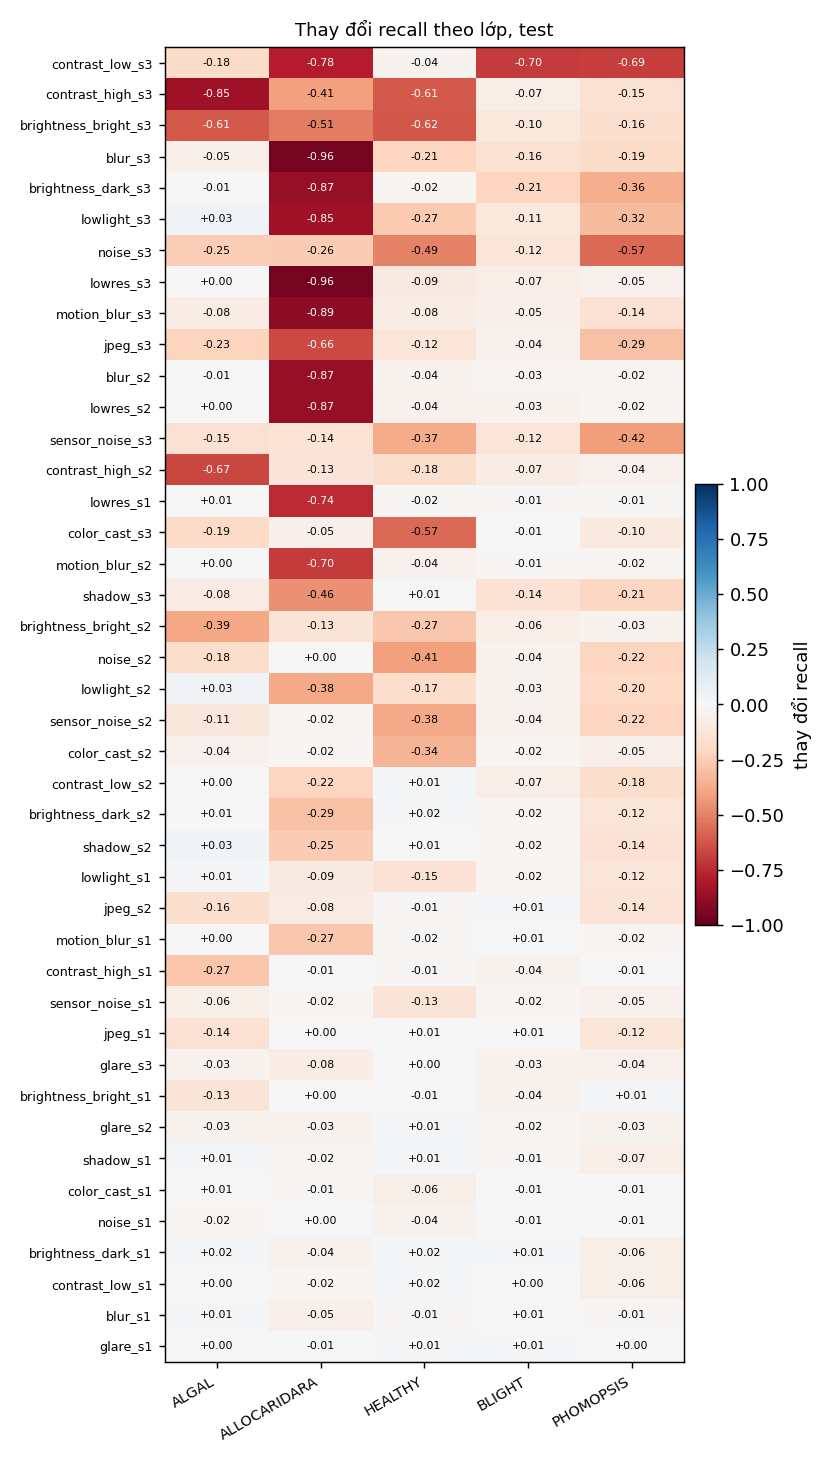

In [9]:
plot_class_recall_change(table_test, classes, FIG / "test_class_recall_change.png", "Thay đổi recall theo lớp, test")
show(FIG / "test_class_recall_change.png")

### Confusion matrix

Chuẩn hóa theo hàng, của ảnh sạch và sáu điều kiện có degradation lớn nhất.

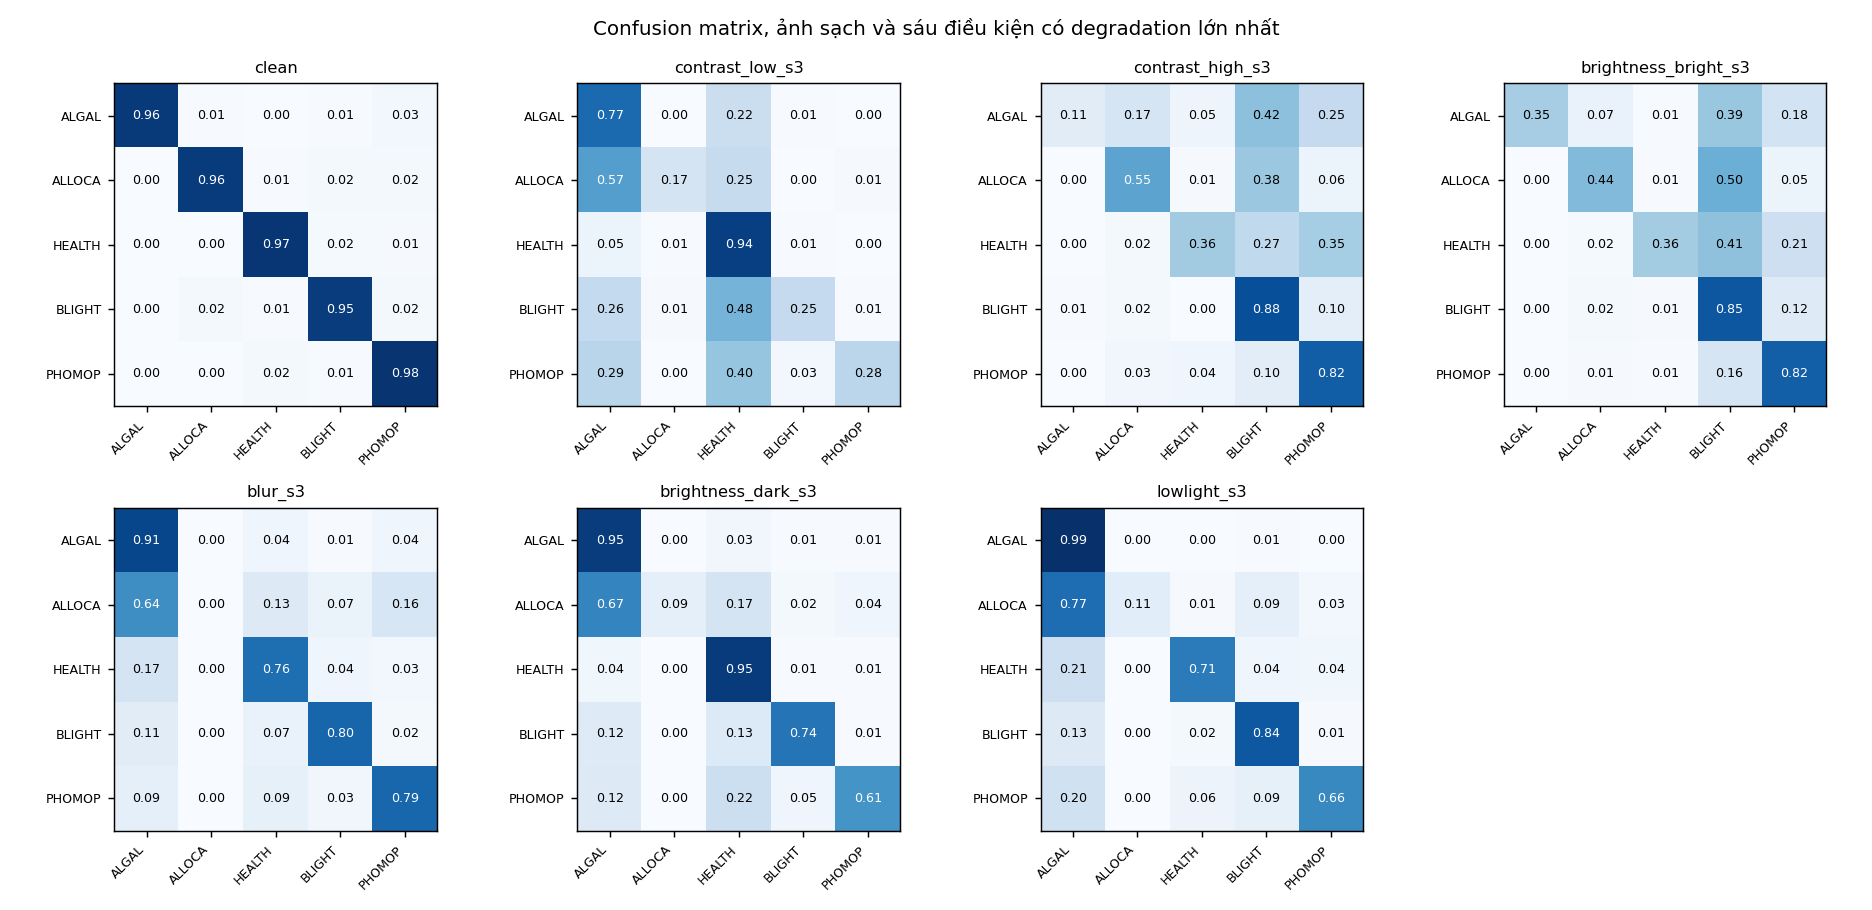

In [10]:
worst = table_test.sort_values("degradation", ascending=False)["condition"].head(6).tolist()
matrices = confusion_matrices(cache_test.labels, probs_test, classes, ["clean", *worst])
plot_confusion_grid(matrices, classes, FIG / "test_confusion_worst.png", "Confusion matrix, ảnh sạch và sáu điều kiện có degradation lớn nhất")
show(FIG / "test_confusion_worst.png")

### Lớp nhận các mẫu bị đổi sang sai

Với các ảnh đúng ở ảnh sạch nhưng sai khi suy giảm, tỉ lệ dự đoán rơi vào từng lớp. Cột chủ yếu một màu nghĩa là dự đoán dồn về một lớp, tức model có lớp mặc định khi ảnh suy giảm. Số bên phải là số ảnh bị đổi.

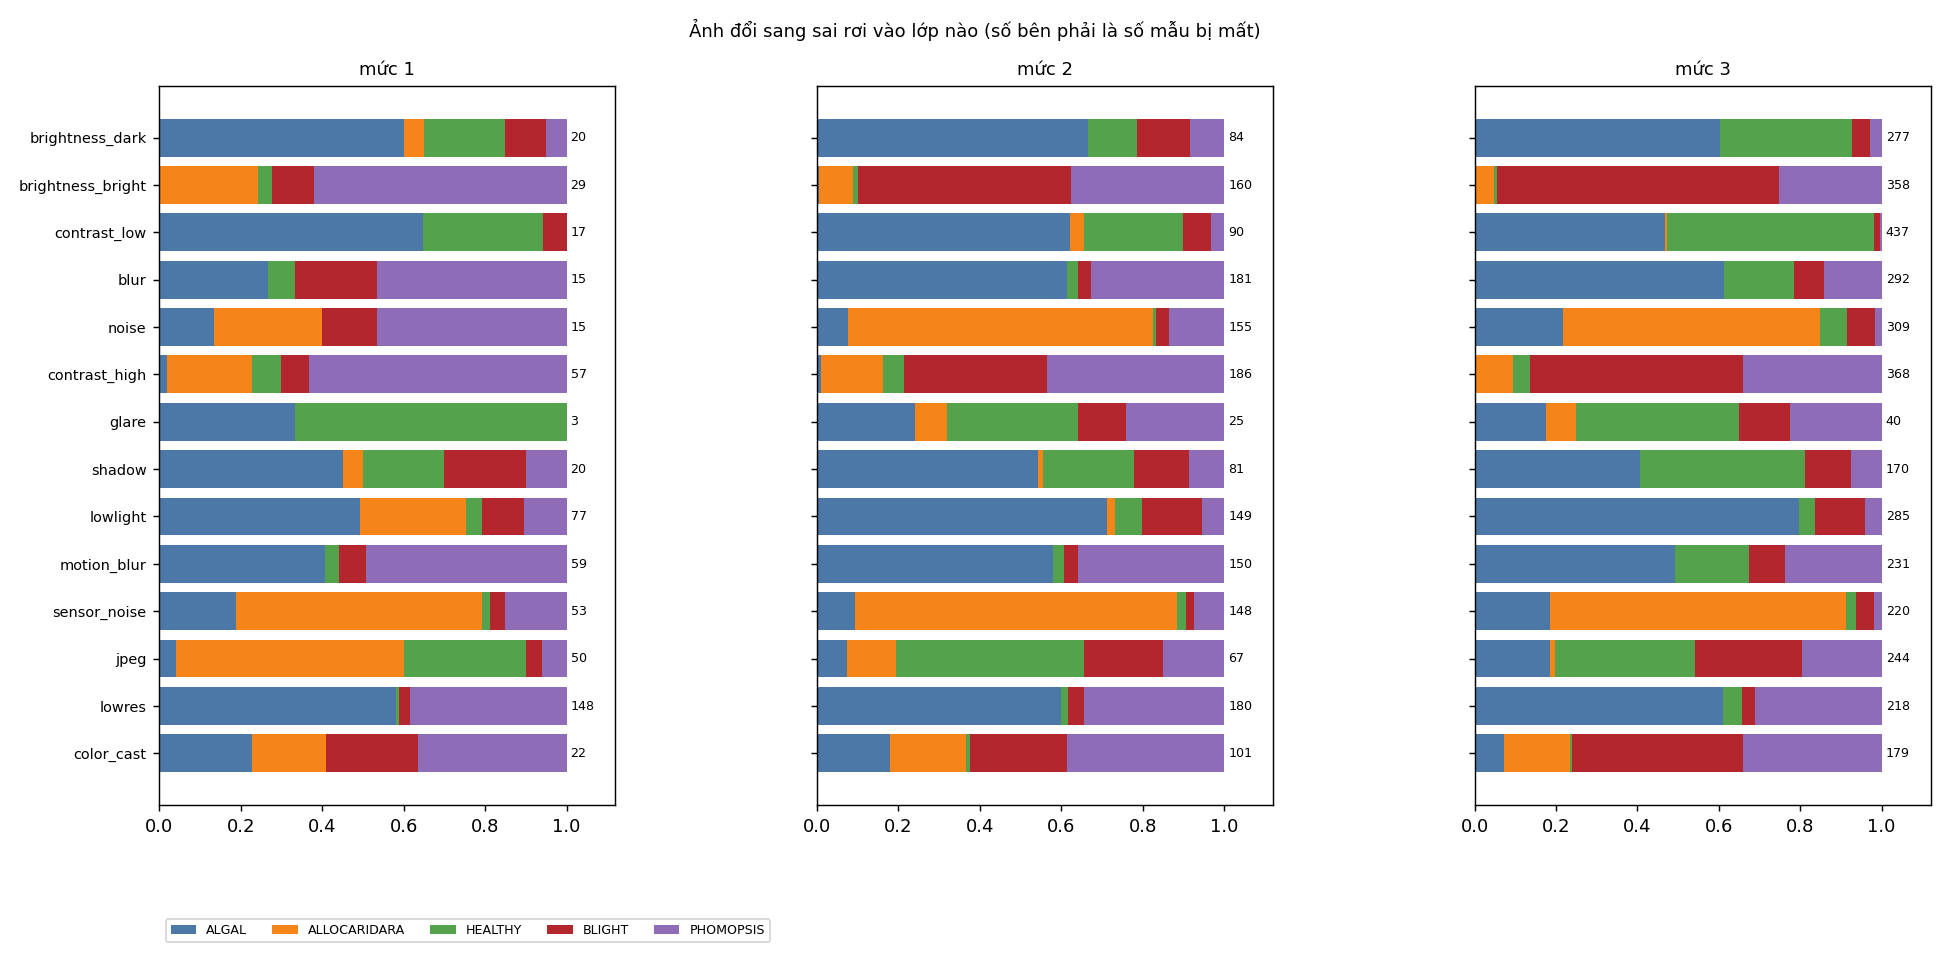

In [11]:
flips = flip_destinations(cache_test.labels, probs_test, classes, list(conditions))
plot_flip_destinations(flips, classes, FIG / "test_flip_destinations.png", "Ảnh đổi sang sai rơi vào lớp nào")
show(FIG / "test_flip_destinations.png")

## 8. Prediction flip theo từng mẫu

Với mỗi ảnh được dự đoán đúng ở ảnh sạch, đếm trên 42 điều kiện bao nhiêu điều kiện làm dự đoán đổi sang sai. Biểu đồ trên là phân bố số lần đổi, hàng dưới là tám ảnh bị đổi nhiều nhất kèm lớp thật và lớp thường bị dự đoán thành.

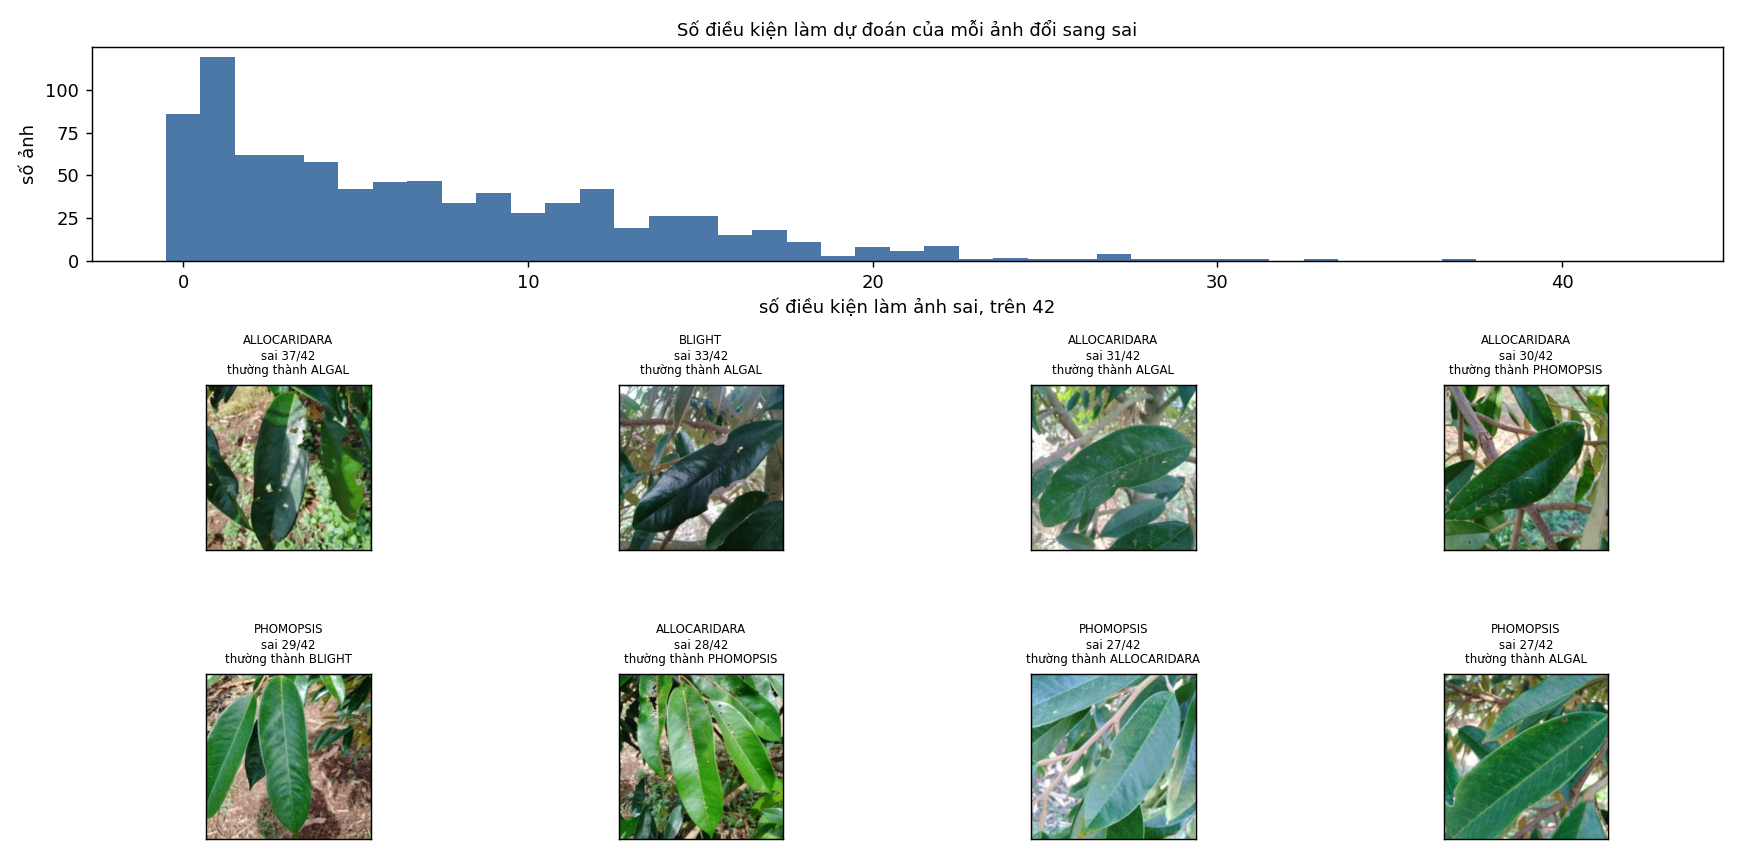

Ảnh không bị đổi ở điều kiện nào: 86/856, bị đổi ở ít nhất một nửa điều kiện: 30


,tỉ lệ điều kiện làm đổi (TB),lớn nhất
label,,
ALGAL_LEAF_SPOT,0.131,0.524
ALLOCARIDARA_ATTACK,0.334,0.881
HEALTHY_LEAF,0.146,0.571
LEAF_BLIGHT,0.074,0.786
PHOMOPSIS_LEAF_SPOT,0.141,0.690


In [12]:
per_sample = sample_flips(cache_test.labels, cache_test.paths, probs_test, classes, list(conditions))
top = int(cfg["flip_top"])
images = cache_test.images.permute(0, 2, 3, 1).numpy()
plot_sample_flips(per_sample, images, len(conditions), top, FIG / "test_sample_flips.png", "Số điều kiện làm dự đoán của mỗi ảnh đổi sang sai")
show(FIG / "test_sample_flips.png")
print(f"Ảnh không bị đổi ở điều kiện nào: {(per_sample['flips'] == 0).sum()}/{len(per_sample)}, bị đổi ở ít nhất một nửa điều kiện: {(per_sample['share'] >= 0.5).sum()}")
display(per_sample.groupby("label")["share"].agg(["mean", "max"]).round(3).rename(columns={"mean": "tỉ lệ điều kiện làm đổi (TB)", "max": "lớn nhất"}))

## 9. Độ nhất quán giữa validation và test

Degradation của 42 điều kiện trên validation (nơi hiệu chỉnh mức) và trên test. Điểm sát đường chéo nghĩa là mức chọn trên validation cho mức giảm tương tự ở test.

{'spearman': 0.9836, 'p_value': 0.0, 'mean_abs_f1_gap': 0.0157, 'max_abs_f1_gap': 0.052}


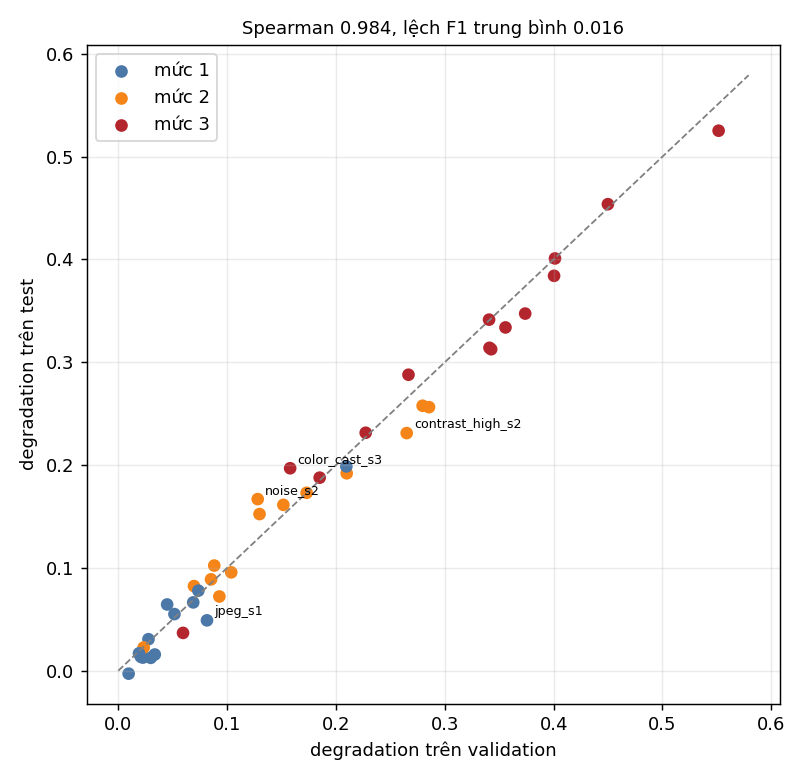

In [13]:
split_check = compare_splits(table_val, table_test)
print({key: round(value, 4) for key, value in split_check.items()})
plot_val_vs_test(table_val, table_test, split_check, FIG / "val_vs_test_degradation.png")
show(FIG / "val_vs_test_degradation.png")

### Thống kê chất lượng ảnh theo mức

Độ sáng, tương phản, độ nét, nhiễu, đo trên 888 ảnh test (kích thước 224 như đầu vào model). Dải xám là khoảng 10 đến 90 phần trăm của ảnh sạch. Mức nào đưa thống kê ra khỏi dải xám nhiều là mức lệch xa phân bố ảnh gốc.

Muốn đối chiếu với ảnh thực địa, đặt `EXTERNAL_ROOT` là thư mục chứa bộ Vietnamese durian leaf trong `/kaggle/input` rồi chạy lại ô này. Khi để `None`, ô chỉ vẽ dải của ảnh sạch.

Chưa có bộ ngoài: bỏ qua đối chiếu thực địa.


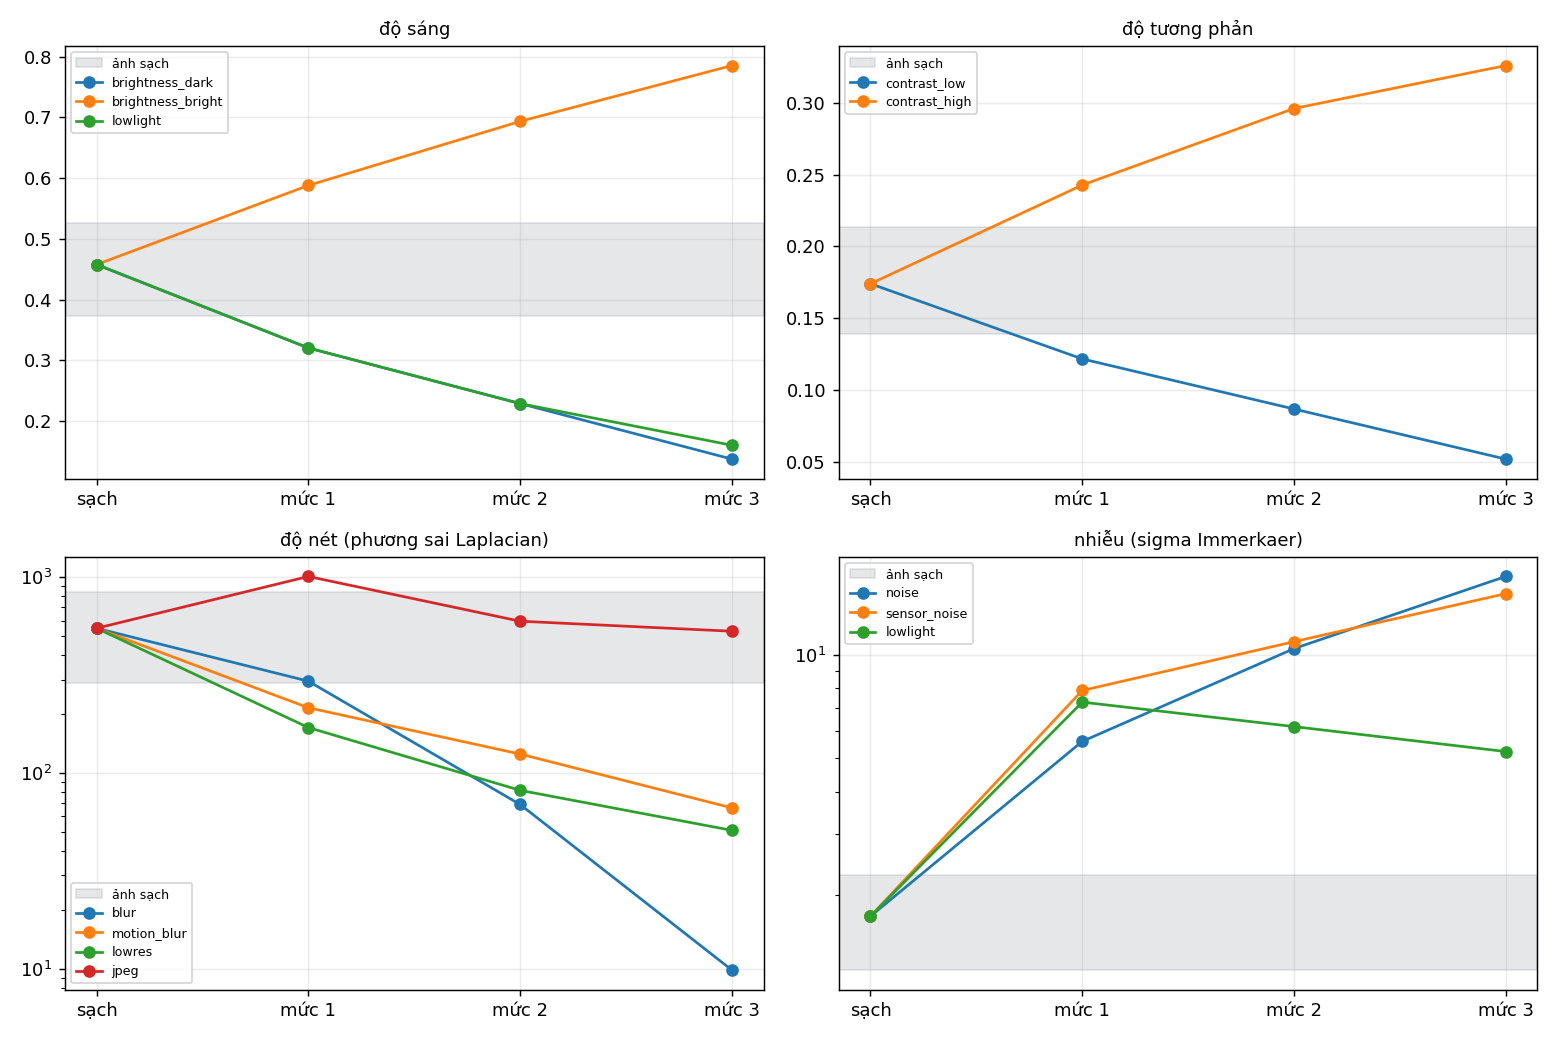

,condition,brightness_mean,contrast_mean,sharpness_mean,noise_mean
0,clean,0.458,0.174,548.201,1.733
3,brightness_dark_s3,0.137,0.052,50.070,0.580
12,blur_s3,0.458,0.154,9.869,0.198
15,noise_s3,0.458,0.184,6155.137,16.931
27,lowlight_s3,0.160,0.064,616.000,5.230
36,jpeg_s3,0.458,0.174,529.379,1.070


In [14]:
EXTERNAL_ROOT = None

summary_quality = quality_summary(quality_test)
clean_quality = summary_quality.set_index("condition").loc["clean"]
external = None
if EXTERNAL_ROOT:
    ext = external_quality(EXTERNAL_ROOT, int(pipeline_cfg["image_size"]), int(cfg["quality"]["external_limit"]))
    external = {stat: (float(ext[stat].quantile(0.1)), float(ext[stat].median()), float(ext[stat].quantile(0.9))) for stat in ["brightness", "contrast", "sharpness", "noise"]}
    display(pd.DataFrame(external, index=["p10", "trung vị", "p90"]).round(3))
else:
    print("Chưa có bộ ngoài: bỏ qua đối chiếu thực địa.")
plot_quality_curves(summary_quality, conditions, clean_quality, external, FIG / "test_quality_curves.png")
show(FIG / "test_quality_curves.png")
display(summary_quality[summary_quality["condition"].isin(["clean", "blur_s3", "noise_s3", "lowlight_s3", "brightness_dark_s3", "jpeg_s3"])][["condition", "brightness_mean", "contrast_mean", "sharpness_mean", "noise_mean"]].round(3))

## 10. Xếp hạng họ suy giảm cho task 4.5

Phân loại họ theo degradation trung bình qua ba mức với ngưỡng đặt trước trong `configs/sensitivity.yaml`: severe từ 0,15, moderate từ 0,05, mild từ 0,02 và có ý nghĩa. Họ giảm từ 0,05 ngay ở mức 1 được đánh dấu `early_drop`: đã giảm đáng kể khi suy giảm còn nhẹ. Nhãn bên phải thanh là task xử lý họ đó.

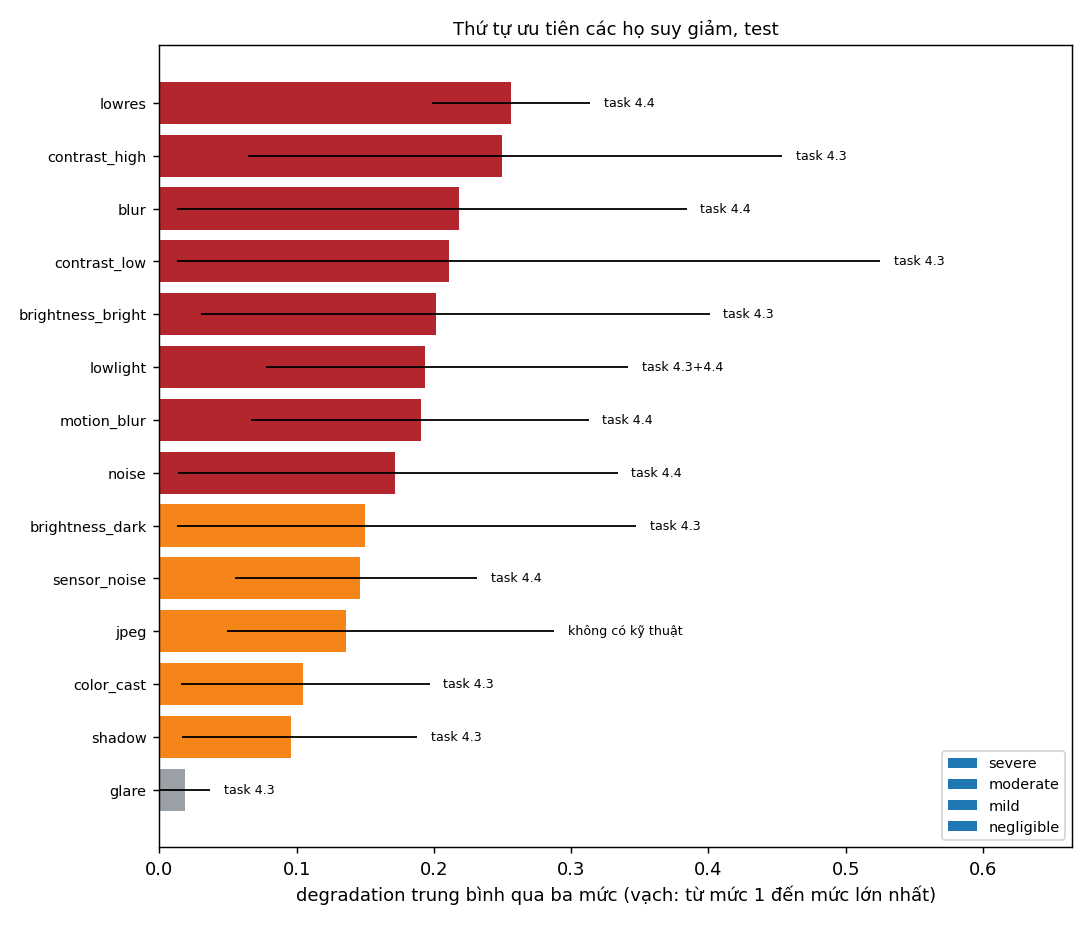

Điều kiện giảm nặng và có ý nghĩa: 31
Họ bị ảnh hưởng nhưng chưa có kỹ thuật xử lý: ['jpeg']
Họ có thể bỏ qua: ['glare']


In [15]:
plan = priority_for_next_task(summary_test, table_test, cfg)
(REP / "priority_for_4_5.json").write_text(json.dumps(plan, indent=2, ensure_ascii=False), encoding="utf-8")
plot_priority(summary_test, FIG / "test_priority.png", "Thứ tự ưu tiên các họ suy giảm, test")
show(FIG / "test_priority.png")
print("Điều kiện giảm nặng và có ý nghĩa:", len(plan["damaging_conditions"]))
print("Họ bị ảnh hưởng nhưng chưa có kỹ thuật xử lý:", plan["without_technique"] or "không có")
print("Họ có thể bỏ qua:", plan["negligible"] or "không có")

## 11. Xuất kết quả

Bảng kết quả nhỏ ghi vào `reports/sensitivity/` để commit. Hình, dự đoán từng ảnh nằm ở `outputs/`. Tất cả được nén vào một file zip để tải về.

In [16]:
import shutil

clean_row = {split: table.attrs["clean"] for split, table in (("val", table_val), ("test", table_test))}
table_test.to_csv(REP / "sensitivity_conditions_test.csv", index=False)
table_val.to_csv(REP / "sensitivity_conditions_val.csv", index=False)
summary_test.drop(columns=["handlers"]).assign(handlers=summary_test["handlers"].map("+".join)).to_csv(REP / "sensitivity_families_test.csv", index=False)
flips.to_csv(RES / "flip_destinations_test.csv", index=False)
per_sample.to_csv(RES / "sample_flips_test.csv", index=False)
summary_quality.to_csv(REP / "quality_by_condition_test.csv", index=False)
(REP / "sensitivity_summary.json").write_text(
    json.dumps({
        "task": "4.2", "reference_model": reference, "corruption_config": cfg["corruption_config"], "seed": seed,
        "samples": {"val": len(cache_val), "test": len(cache_test)}, "clean": clean_row,
        "split_agreement": split_check, "bootstrap": cfg["bootstrap"], "alpha": cfg["alpha"],
        "significant_conditions_test": int(table_test["significant"].sum()), "conditions": len(table_test),
        "external_quality": external,
        "note": "Một model, một seed huấn luyện. Khoảng tin cậy chỉ phản ánh độ ngẫu nhiên của việc chọn mẫu test.",
    }, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
archive = shutil.make_archive("/kaggle/working/sensitivity_outputs", "zip", root_dir=REPO_DIR, base_dir="outputs/figures/sensitivity")
shutil.make_archive("/kaggle/working/sensitivity_reports", "zip", root_dir=REPO_DIR, base_dir="reports/sensitivity")
print("Đã lưu:", sorted(path.name for path in REP.iterdir()))

Đã lưu: ['priority_for_4_5.json', 'quality_by_condition_test.csv', 'sensitivity_conditions_test.csv', 'sensitivity_conditions_val.csv', 'sensitivity_families_test.csv', 'sensitivity_summary.json']
